In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv("/content/mall.csv")

print(df.head())
print(df.shape)
print(df.dtypes)
print(df.duplicated().sum())
print(df.drop_duplicates(inplace=True))
print(df.shape)

   INCOME  SPEND
0     307    191
1     272    211
2     316    191
3     364    200
4     267    143
(700, 2)
INCOME    int64
SPEND     int64
dtype: object
10
None
(690, 2)


In [3]:
df.columns

Index(['INCOME', 'SPEND'], dtype='object')

In [7]:
df.isnull().sum()

,0
INCOME,0
SPEND,0


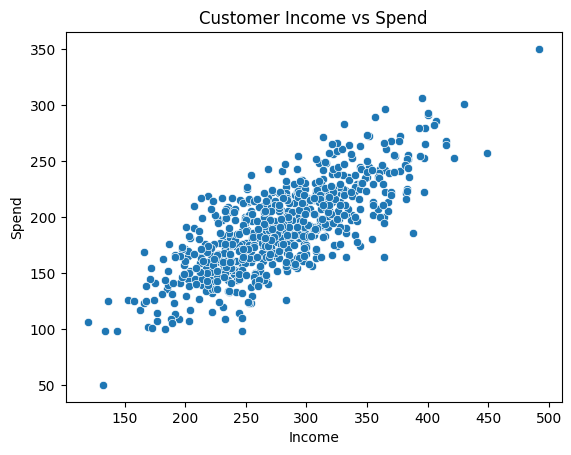

In [13]:
sns.scatterplot(x=df["INCOME"], y=df["SPEND"])

plt.xlabel("Income")
plt.ylabel("Spend")
plt.title("Customer Income vs Spend")
plt.show()

In [14]:
df_copy = df.copy()

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

df = ss.fit_transform(df)

In [15]:
from sklearn.cluster import KMeans

SSE = []
K_cluster = []

for k in range(1,21):

    km = KMeans(n_clusters=k)

    km.fit(df)
    SSE.append(km.inertia_)
    K_cluster.append(k)

In [16]:
dict = {
    'Value Of K': K_cluster,
    'SSE': SSE
}

df1 = pd.DataFrame(dict)

df1

,Value Of K,SSE
0,1,1380.000000
1,2,626.071723
2,3,403.490780
3,4,316.816255
4,5,269.507840
5,6,221.733115
6,7,196.938687
7,8,171.319892
8,9,158.618917
9,10,138.168727


<Axes: xlabel='Value Of K', ylabel='SSE'>

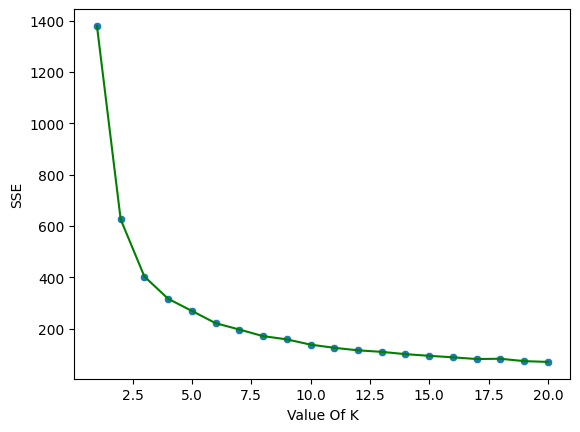

In [20]:
sns.scatterplot(
    data=df1,
    x='Value Of K',
    y='SSE'
)

sns.lineplot(
    data=df1,
    x='Value Of K',
    y='SSE',
    color='green'
)

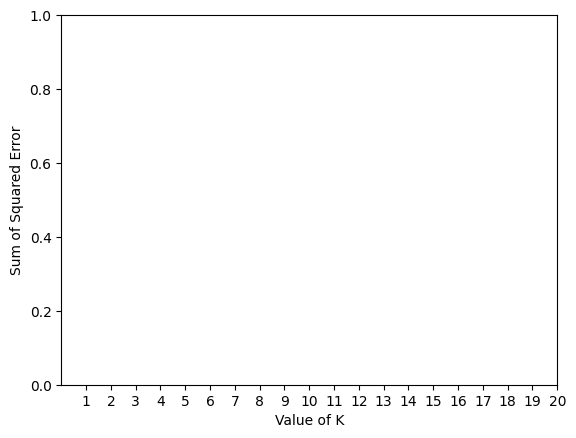

In [21]:
plt.xlabel('Value of K')
plt.ylabel('Sum of Squared Error')
plt.xticks(df1['Value Of K'])

plt.show()

In [23]:
km = KMeans(
    n_clusters=5,
    random_state=1
)
Y_pred = km.fit_predict(df)
Y_pred

array([1, 1, 1, 4, 0, 1, 4, 4, 3, 4, 0, 0, 1, 3, 3, 0, 0, 1, 3, 3, 4, 0,
       0, 3, 0, 1, 3, 1, 0, 0, 0, 4, 1, 3, 4, 3, 1, 3, 0, 1, 1, 0, 0, 0,
       3, 0, 0, 4, 1, 3, 1, 0, 3, 4, 1, 2, 0, 0, 1, 4, 0, 0, 0, 3, 4, 4,
       1, 4, 1, 1, 1, 4, 1, 2, 3, 1, 0, 0, 1, 3, 0, 1, 4, 0, 0, 0, 4, 1,
       0, 1, 1, 4, 0, 0, 0, 3, 1, 1, 1, 0, 3, 0, 0, 0, 0, 1, 2, 1, 1, 0,
       3, 0, 1, 2, 1, 0, 1, 0, 4, 4, 1, 0, 2, 3, 1, 2, 0, 0, 1, 0, 3, 0,
       3, 1, 0, 4, 0, 0, 4, 3, 1, 4, 3, 1, 1, 4, 3, 0, 1, 1, 1, 1, 0, 1,
       4, 0, 4, 1, 3, 4, 0, 1, 4, 0, 1, 1, 4, 2, 1, 1, 0, 3, 0, 1, 1, 4,
       0, 4, 0, 2, 4, 3, 3, 4, 1, 4, 1, 0, 0, 3, 0, 4, 1, 0, 1, 1, 1, 1,
       3, 1, 1, 4, 4, 3, 0, 1, 4, 4, 2, 1, 4, 4, 4, 0, 4, 0, 0, 0, 1, 2,
       3, 1, 3, 1, 1, 0, 0, 0, 1, 0, 4, 0, 3, 2, 1, 3, 1, 0, 1, 3, 1, 4,
       0, 0, 3, 0, 4, 1, 3, 4, 4, 4, 3, 0, 4, 0, 1, 4, 0, 1, 3, 0, 0, 0,
       4, 0, 0, 0, 4, 3, 4, 0, 3, 0, 1, 3, 0, 0, 1, 4, 4, 3, 2, 3, 1, 4,
       1, 0, 0, 3, 0, 1, 1, 0, 4, 1, 1, 4, 0, 0, 4,

In [24]:
df_copy['Target'] = Y_pred

df_copy.head()
df_0 = df_copy[df_copy['Target'] == 0]
df_1 = df_copy[df_copy['Target'] == 1]
df_2 = df_copy[df_copy['Target'] == 2]
df_3 = df_copy[df_copy['Target'] == 3]
df_4 = df_copy[df_copy['Target'] == 4]
df_0.shape, df_1.shape, df_2.shape, df_3.shape, df_4.shape

((205, 3), (218, 3), (33, 3), (111, 3), (123, 3))

In [26]:
km.cluster_centers_
ss.inverse_transform(km.cluster_centers_)

array([[252.32682927, 172.75121951],
       [294.69545455, 200.05909091],
       [390.27272727, 272.33333333],
       [204.27927928, 137.21621622],
       [337.3553719 , 230.32231405]])

<Axes: xlabel='INCOME', ylabel='SPEND'>

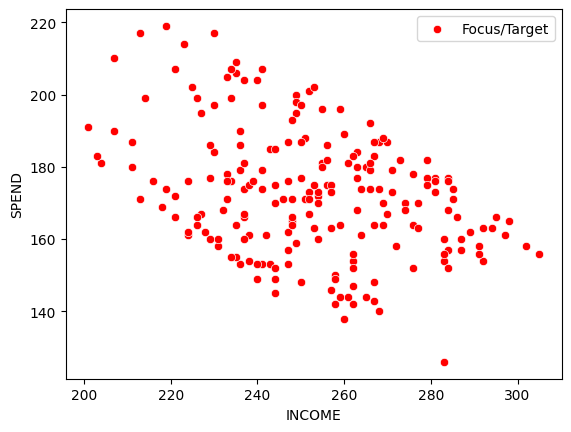

In [27]:
sns.scatterplot(
    data=df_0,
    x="INCOME",
    y="SPEND",
    color="red",
    label="Focus/Target"
)

<Axes: xlabel='INCOME', ylabel='SPEND'>

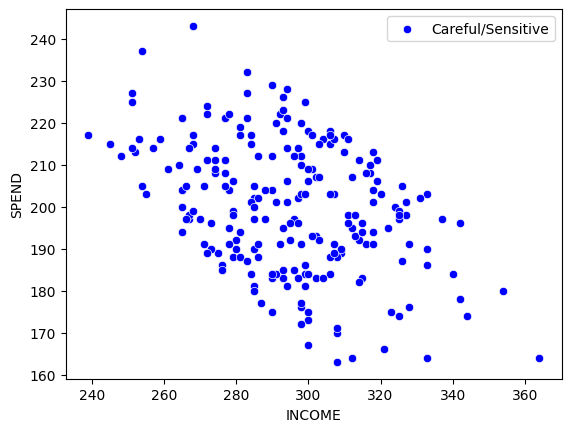

In [28]:
sns.scatterplot(
    data=df_1,
    x="INCOME",
    y="SPEND",
    color="blue",
    label="Careful/Sensitive"
)

<Axes: xlabel='INCOME', ylabel='SPEND'>

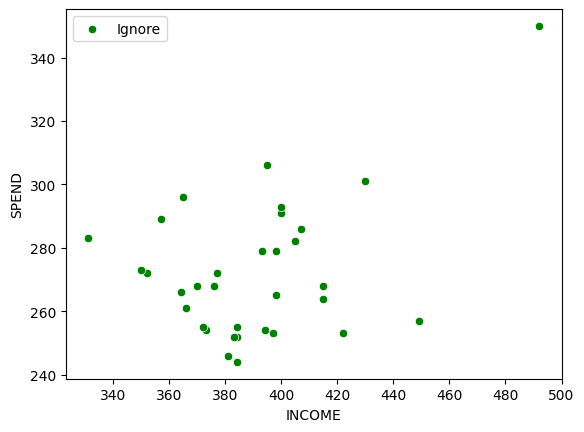

In [29]:
sns.scatterplot(
    data=df_2,
    x="INCOME",
    y="SPEND",
    color="green",
    label="Ignore"
)

<Axes: xlabel='INCOME', ylabel='SPEND'>

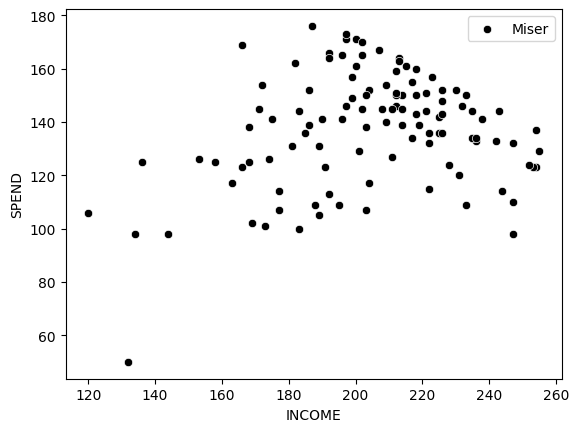

In [30]:
sns.scatterplot(
    data=df_3,
    x="INCOME",
    y="SPEND",
    color="black",
    label="Miser"
)

<Axes: xlabel='INCOME', ylabel='SPEND'>

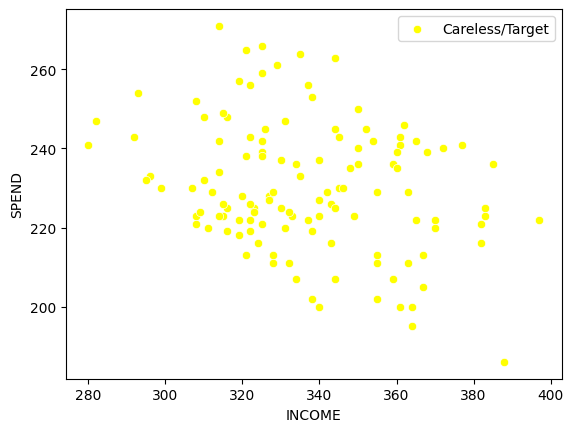

In [31]:
sns.scatterplot(
    data=df_4,
    x="INCOME",
    y="SPEND",
    color="yellow",
    label="Careless/Target"
)

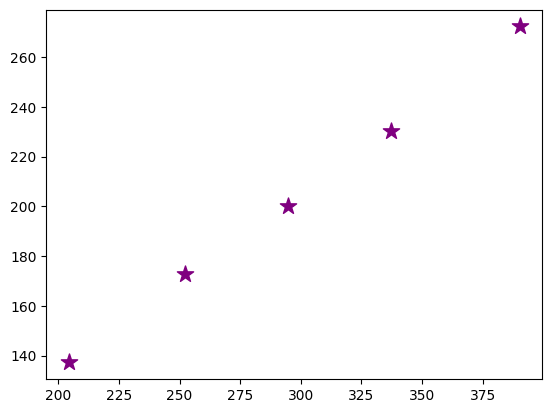

In [32]:
plt.scatter(
    ss.inverse_transform(km.cluster_centers_)[:,0],
    ss.inverse_transform(km.cluster_centers_)[:,1],
    color="purple",
    marker="*",
    s=150
)

plt.show()

In [33]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

df_scaled = ss.fit_transform(df)

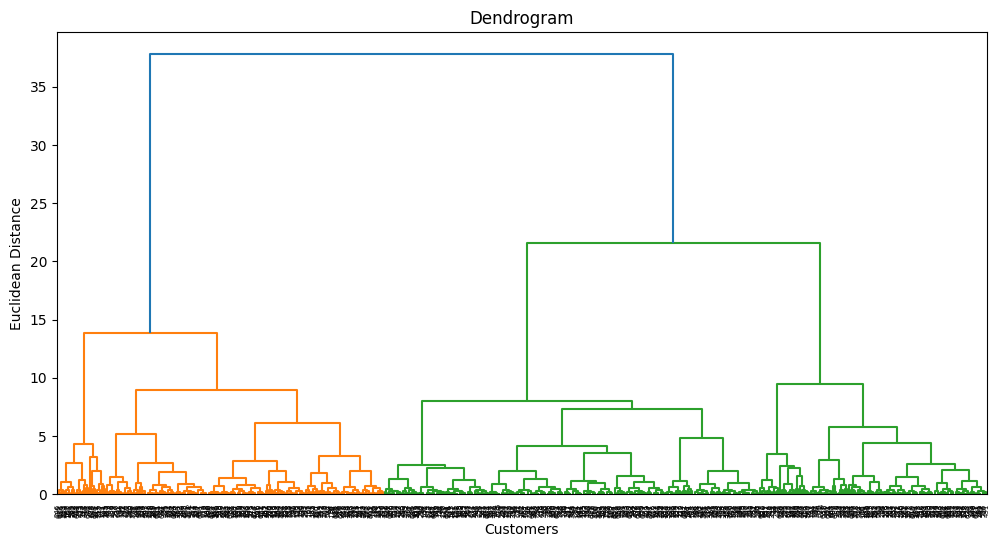

In [35]:
linked = linkage(
    df_scaled,
    method='ward'
)

plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")

plt.show()

In [36]:
hc = AgglomerativeClustering(
    n_clusters=5
)

y_pred = hc.fit_predict(df_scaled)
y_pred

array([0, 2, 0, 0, 1, 2, 0, 0, 1, 0, 2, 2, 2, 4, 4, 2, 1, 2, 1, 1, 0, 1,
       2, 1, 2, 2, 1, 2, 2, 2, 2, 0, 2, 1, 0, 1, 2, 4, 1, 0, 0, 2, 2, 2,
       1, 1, 2, 0, 2, 4, 2, 1, 1, 0, 0, 3, 2, 2, 2, 0, 2, 2, 2, 1, 0, 0,
       2, 0, 2, 2, 0, 0, 2, 3, 4, 0, 2, 2, 2, 4, 2, 2, 0, 2, 2, 2, 0, 2,
       2, 2, 2, 0, 2, 1, 1, 1, 2, 0, 2, 2, 1, 2, 2, 1, 2, 2, 3, 2, 0, 2,
       4, 2, 0, 3, 2, 2, 2, 1, 0, 0, 0, 2, 3, 1, 0, 3, 2, 2, 2, 2, 4, 2,
       1, 2, 1, 0, 2, 1, 0, 1, 2, 0, 4, 2, 2, 0, 1, 2, 0, 2, 2, 2, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 2, 0, 2, 0, 3, 2, 2, 1, 1, 2, 2, 2, 0,
       2, 0, 2, 3, 0, 1, 1, 0, 2, 0, 0, 2, 2, 1, 2, 0, 0, 1, 0, 0, 2, 2,
       1, 2, 0, 0, 0, 1, 1, 2, 0, 0, 3, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 3,
       4, 0, 4, 2, 0, 2, 1, 2, 0, 1, 0, 2, 1, 3, 0, 4, 0, 2, 0, 1, 2, 0,
       2, 1, 1, 1, 3, 2, 1, 0, 0, 0, 4, 2, 0, 2, 0, 0, 2, 2, 4, 2, 2, 1,
       0, 1, 2, 2, 0, 4, 0, 2, 1, 2, 2, 1, 2, 2, 0, 0, 0, 1, 3, 4, 2, 0,
       2, 2, 2, 1, 2, 0, 2, 2, 0, 0, 0, 0, 2, 2, 0,

In [37]:
df_copy['Target'] = y_pred

df_copy.head()
df_h0 = df_copy[df_copy['Target'] == 0]
df_h1 = df_copy[df_copy['Target'] == 1]
df_h2 = df_copy[df_copy['Target'] == 2]
df_h3 = df_copy[df_copy['Target'] == 3]
df_h4 = df_copy[df_copy['Target'] == 4]
df_h0.shape, df_h1.shape, df_h2.shape, df_h3.shape, df_h4.shape

((206, 3), (132, 3), (278, 3), (37, 3), (37, 3))

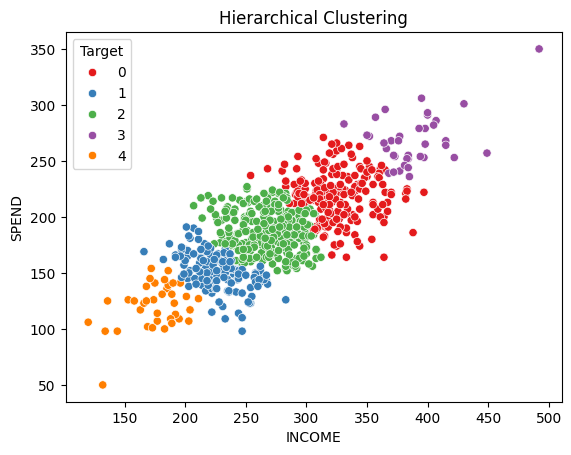

In [38]:
sns.scatterplot(
    data=df_copy,
    x='INCOME',
    y='SPEND',
    hue='Target',
    palette='Set1'
)
plt.title("Hierarchical Clustering")
plt.show()